# Session 7 lecture: Time series and trends

<p class="lead">
A number on its own says little; the same number compared with the right earlier period says a lot. This lecture shows how to read a series over time, pick a fair comparison, smooth out the noise and avoid the traps that make ordinary months look like disasters.
</p>

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Aayush181509/AnalyticsLecture/blob/main/notebooks/07_trends_and_growth_lecture.ipynb)

Open this notebook in Google Colab with the button above, then run each cell from top to bottom with **Shift + Enter**. Save your own copy with **File → Save a copy in Drive**.

---

## Recap quiz

Before we start, answer the quiz at the end of the [Session 6 lecture](06_visualisation_principles_lecture.md). Write short answers; we discuss them together.

---

## What you will be able to explain

1. The three **components** of a time series: trend, seasonality and noise.
2. When **month-on-month** and when **year-on-year** growth is the fair comparison.
3. How a **rolling average** smooths a series, and the difference between **trailing** and **centred** windows.
4. How **index numbers** (base = 100) let you compare series of very different sizes.
5. What a **seasonally adjusted** series is, and why official statistics publish one.
6. Why **incomplete** and **missing** periods break comparisons, and how to guard against them.
7. Why growth must be computed **before** you filter to a period.

This lecture builds on the section on cherry-picked time windows in [How statistics can mislead](../foundations/misleading-statistics.md). In the **Lab** you apply every idea to the retail orders and to official US construction spending.

> **How to use the questions in this notebook**
>
> **Predict, then reveal** boxes ask you to guess before running the next cell. Write your guess down first. **Check your understanding** boxes are short questions to answer in your own words.

Run the setup cell first. For the demonstrations we also use **numpy** to simulate a small monthly series. A fixed **seed** makes the "random" numbers the same every time, so your output matches everyone else's.

In [1]:
# Course data setup. Run this cell first; you do not need to understand it yet.
# It downloads the Superstore sample from Tableau's website, checks it is the
# exact version this course was written for, and prepares the order-lines table.
import hashlib
import os
import urllib.request

import matplotlib.pyplot as plt
import pandas as pd

SOURCE_URL = "https://public.tableau.com/app/sample-data/sample_-_superstore.xls"
EXPECTED_SHA256 = "5045ed4fec49cae2cc0dfc5ab0d204ba09efa767fe00c996822499e8cc42fbbd"
SOURCE_FILE = os.environ.get("COURSE_XLS_PATH", "sample_-_superstore.xls")

try:
    import xlrd  # noqa: F401  (needed to read .xls files)
except ImportError:
    import subprocess
    import sys

    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "xlrd"])

if not os.path.exists(SOURCE_FILE):
    urllib.request.urlretrieve(SOURCE_URL, SOURCE_FILE)

with open(SOURCE_FILE, "rb") as f:
    digest = hashlib.sha256(f.read()).hexdigest()
if digest != EXPECTED_SHA256:
    print("WARNING: Tableau has changed this sample file since the course was written.")
    print("Your numbers will differ from the lesson. Ask your facilitator for the course copy.")


def load_orders():
    """Return one row per order line, orders placed 2023-01-01 to 2025-12-31."""
    raw = pd.read_excel(SOURCE_FILE, sheet_name="Orders")
    returns = pd.read_excel(SOURCE_FILE, sheet_name="Returns")

    # Orders with more than one Customer ID (a known data issue), found before filtering.
    ids_per_order = raw.groupby("Order ID")["Customer ID"].nunique()
    conflict_orders = set(ids_per_order[ids_per_order > 1].index)

    in_scope = (raw["Order Date"] >= "2023-01-01") & (raw["Order Date"] < "2026-01-01")
    df = raw.loc[in_scope].copy()

    df = df.rename(columns={
        "Row ID": "row_id", "Order ID": "order_id", "Order Date": "order_date",
        "Ship Date": "ship_date", "Ship Mode": "ship_mode", "Customer ID": "customer_id",
        "Segment": "segment", "Country/Region": "country_region", "Region": "region",
        "Category": "category", "Sub-Category": "sub_category", "Product ID": "product_id",
        "Product Name": "product_name", "Sales": "sales", "Quantity": "quantity",
        "Discount": "discount", "Profit": "profit",
    })
    df["returned_order_flag"] = df["order_id"].isin(set(returns["Order ID"])).astype(int)
    df["customer_order_conflict"] = df["order_id"].isin(conflict_orders).astype(int)
    df["customer_analysis_eligible"] = 1 - df["customer_order_conflict"]
    df["order_to_ship_days"] = (df["ship_date"] - df["order_date"]).dt.days
    df["order_month"] = df["order_date"].dt.to_period("M").dt.to_timestamp()

    columns = [
        "row_id", "order_id", "order_date", "ship_date", "ship_mode", "customer_id",
        "segment", "country_region", "region", "category", "sub_category", "product_id",
        "product_name", "sales", "quantity", "discount", "profit", "returned_order_flag",
        "customer_analysis_eligible", "customer_order_conflict", "order_to_ship_days",
        "order_month",
    ]
    return df[columns].sort_values("row_id").reset_index(drop=True)


pd.set_option("display.float_format", "{:,.2f}".format)
plt.rcParams.update({
    "figure.figsize": (8, 4),
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "axes.axisbelow": True,
    "grid.color": "#e6e5e1",
    "axes.prop_cycle": plt.cycler(color=["#2a78d6", "#eb6834", "#1baf7a"]),
    "axes.titleweight": "bold",
    "axes.titlelocation": "left",
})
print("Setup complete.")

Setup complete.


In [2]:
import numpy as np

df = load_orders()
print("Order lines:", len(df))

Order lines: 6815


---

## Part 1: The three components of a series

A **time series** is one measure recorded at regular intervals: Sales per month, visitors per day, spending per quarter. Most business series are a mix of three parts:

| Component | What it is | Example |
|---|---|---|
| **Trend** | The slow, long-run direction | A shop growing a little every year |
| **Seasonality** | A pattern that repeats at the same time every year (or week, or day) | Busy Novembers and Decembers, quiet Januaries |
| **Noise** | Irregular ups and downs with no pattern | A delivery delay, one big one-off order |

The cell below **builds** a series from these three parts, so we know exactly what is inside it. Real data never tells you its parts; you have to infer them.

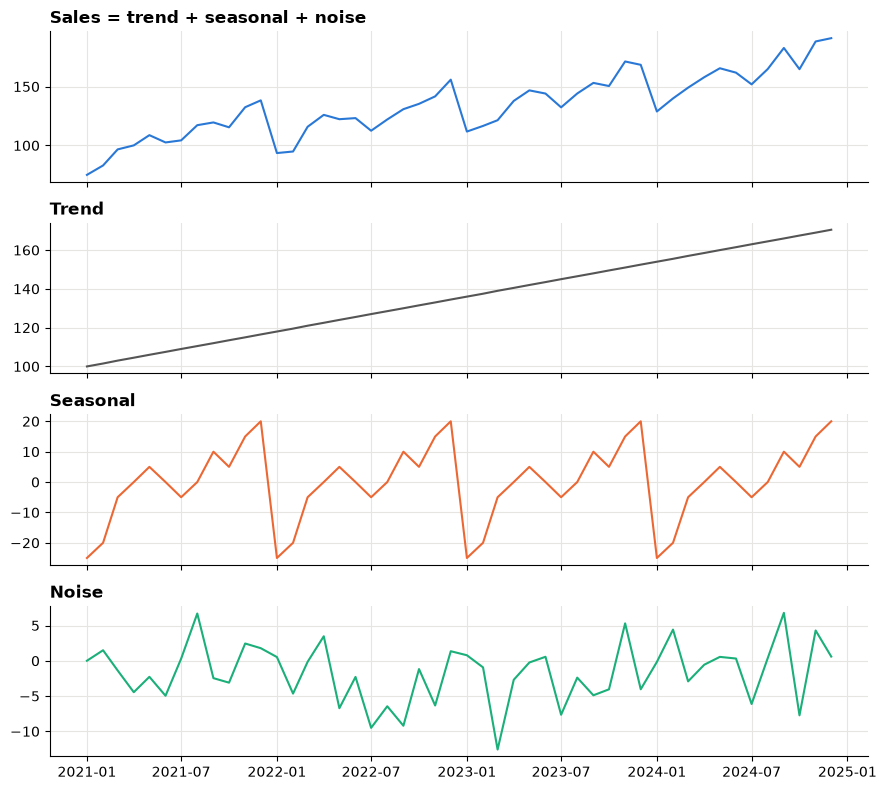

In [3]:
rng = np.random.default_rng(seed=7)
months = pd.date_range("2021-01-01", "2024-12-01", freq="MS")
t = np.arange(len(months))

trend = 100 + 1.5 * t                                   # grows steadily every month
season_by_month = [-25, -20, -5, 0, 5, 0, -5, 0, 10, 5, 15, 20]   # same shape every year
seasonal = np.array([season_by_month[m.month - 1] for m in months])
noise = rng.normal(0, 5, len(months))

demo = pd.DataFrame({"trend": trend, "seasonal": seasonal, "noise": noise}, index=months)
demo["sales"] = demo["trend"] + demo["seasonal"] + demo["noise"]

fig, axes = plt.subplots(4, 1, figsize=(9, 8), sharex=True)
for ax, col, colour in zip(axes, ["sales", "trend", "seasonal", "noise"],
                           ["#2a78d6", "#555555", "#eb6834", "#1baf7a"]):
    ax.plot(demo.index, demo[col], color=colour)
    ax.set_title(col.capitalize() if col != "sales" else "Sales = trend + seasonal + noise")
fig.tight_layout()
plt.show()

> **Predict, then reveal**
>
> Look only at the top panel. Between December and January of each year, does the series go up or down? Is that the **trend** changing, or something else? Now look at the three panels underneath and check.

The top line drops every January even though the trend never stops rising. A manager looking only at the latest two months would see a "fall" that is entirely seasonal.

> **Check your understanding 1**
>
> Name one business series you know and describe its likely trend, its seasonality and one source of noise.

---

## Part 2: Month-on-month versus year-on-year

Growth always compares two values: *(this period − comparison period) ÷ comparison period*. The question is **which** comparison period.

| Growth type | Compares with | pandas |
|---|---|---|
| **Month-on-month (MoM)** | the previous month | `pct_change()` |
| **Year-on-year (YoY)** | the same month a year earlier | `pct_change(periods=12)` |

> **Predict, then reveal**
>
> In the simulated series, the trend rises a little every month. What do you expect January's **MoM** growth to look like? And January's **YoY** growth?

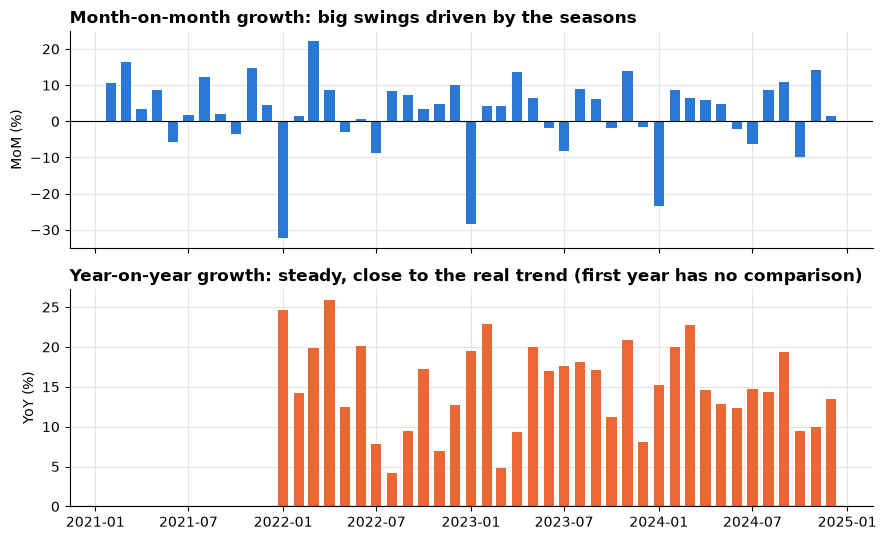

,sales,mom,yoy
2021-01-01,75.01,no comparison,no comparison
2022-01-01,93.53,-32.4%,+24.7%
2023-01-01,111.78,-28.3%,+19.5%
2024-01-01,128.84,-23.5%,+15.3%


In [4]:
demo["mom"] = demo["sales"].pct_change()
demo["yoy"] = demo["sales"].pct_change(periods=12)

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(9, 5.5), sharex=True)
ax1.bar(demo.index, demo["mom"] * 100, width=20)
ax1.axhline(0, color="black", linewidth=0.8)
ax1.set_title("Month-on-month growth: big swings driven by the seasons")
ax1.set_ylabel("MoM (%)")
ax2.bar(demo.index, demo["yoy"] * 100, width=20, color="#eb6834")
ax2.axhline(0, color="black", linewidth=0.8)
ax2.set_title("Year-on-year growth: steady, close to the real trend (first year has no comparison)")
ax2.set_ylabel("YoY (%)")
fig.tight_layout()
plt.show()

def as_pct(value):
    return "no comparison" if pd.isna(value) else f"{value:+.1%}"


januaries = demo[demo.index.month == 1][["sales", "mom", "yoy"]]
januaries.assign(mom=januaries["mom"].map(as_pct), yoy=januaries["yoy"].map(as_pct))

Read the table above. Every January has a large negative MoM figure, while YoY stays positive. The first January has no comparison at all: pandas stores it as `NaN` (*not a number*), and our `as_pct` helper prints it as "no comparison", never as zero.

| Use… | When… | Watch out for… |
|---|---|---|
| **MoM** | You need to spot a sudden change quickly, and the series is not strongly seasonal | Seasonal swings that look like booms and crashes |
| **YoY** | The business is seasonal and you want like-for-like | A one-off event in the same month last year; it reacts slowly to new changes |

> **Blank is not zero**
>
> A growth value with no comparison period is **not available**. It is not 0%. Never fill it with 0.

> **Check your understanding 2**
>
> A colleague reports "Sales up 40% month-on-month in November". What extra comparison would you ask for before celebrating, and why?

---

## Part 3: Rolling averages, trailing and centred

A **rolling average** (or moving average) replaces each value with the average of a window of neighbouring values. A 12-month window covers exactly one full year, so every month of the season appears once and the seasonal pattern cancels out.

| Window | Uses | Good for | Cost |
|---|---|---|---|
| **Trailing** | this month and the 11 before it | Dashboards: only uses data you already have | It **lags**: it turns late |
| **Centred** | about 6 months either side | Seeing exactly *when* the trend turned | Needs future data, so the last months are blank |

We add a sudden **step**: from mid-2023, sales jump by 40 and stay there.

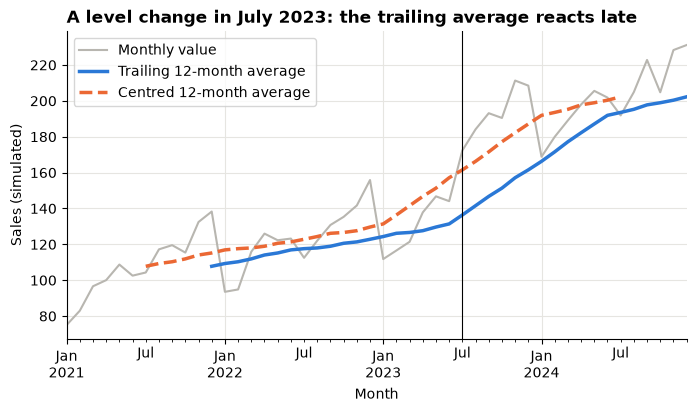

Blank trailing values: 11 | blank centred values: 11


In [5]:
stepped = demo["sales"] + np.where(demo.index >= "2023-07-01", 40, 0)

smooth = pd.DataFrame({
    "monthly": stepped,
    "trailing 12": stepped.rolling(12).mean(),
    "centred 12": stepped.rolling(12, center=True).mean(),
})

ax = smooth["monthly"].plot(color="#b8b6b0", label="Monthly value")
smooth["trailing 12"].plot(ax=ax, color="#2a78d6", linewidth=2.5, label="Trailing 12-month average")
smooth["centred 12"].plot(ax=ax, color="#eb6834", linewidth=2.5, linestyle="--", label="Centred 12-month average")
ax.axvline(pd.Timestamp("2023-07-01"), color="black", linewidth=0.8)
ax.set_title("A level change in July 2023: the trailing average reacts late")
ax.set_xlabel("Month")
ax.set_ylabel("Sales (simulated)")
ax.legend()
plt.show()

print("Blank trailing values:", smooth["trailing 12"].isna().sum(),
      "| blank centred values:", smooth["centred 12"].isna().sum())

> **Predict, then reveal**
>
> Before reading the chart: which line will finish its climb closer to the vertical line in July 2023, the trailing or the centred average? Where will each line be blank?

The trailing average needs 11 earlier months, so it is blank at the **start**. The centred average needs months on both sides, so it is blank at **both ends**, including the most recent months a manager usually cares about most.

> **Check your understanding 3**
>
> You are building a monthly dashboard that updates on the first day of each month. Which rolling average can you show for the latest month, and what will it hide?

---

## Part 4: Index numbers (base = 100)

Two series of very different sizes are hard to compare on one chart: the big one squashes the small one flat. An **index** divides every value by the value in a chosen **base period** and multiplies by 100.

*index = value ÷ base value × 100*

So the base period is 100 for every series, and 120 later means "20% above the base period". We add up each segment's Sales by year and use 2023 as the base year. A whole year as the base means one unusual month cannot distort it.

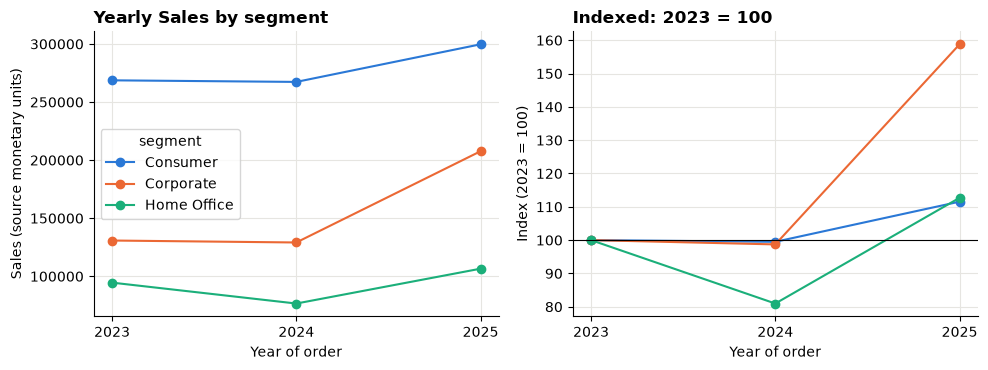

segment,Consumer,Corporate,Home Office
order_month,,,
2023,100.00,100.00,100.00
2024,99.50,98.70,81.00
2025,111.50,158.80,112.70


In [6]:
seg_monthly = df.groupby(["order_month", "segment"])["sales"].sum().unstack()
seg_yearly = seg_monthly.groupby(seg_monthly.index.year).sum()

base = seg_yearly.loc[2023]
index = seg_yearly / base * 100

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 3.8))
seg_yearly.plot(ax=ax1, marker="o", title="Yearly Sales by segment")
ax1.set_ylabel("Sales (source monetary units)")
ax1.set_xticks(seg_yearly.index)
ax1.set_xlabel("Year of order")
index.plot(ax=ax2, marker="o", title="Indexed: 2023 = 100", legend=False)
ax2.axhline(100, color="black", linewidth=0.8)
ax2.set_ylabel("Index (2023 = 100)")
ax2.set_xticks(index.index)
ax2.set_xlabel("Year of order")
fig.tight_layout()
plt.show()

index.round(1)

On the left, the largest segment dominates. On the right, every segment starts at 100, so you compare **growth paths**, not sizes.

> **Check your understanding 4**
>
> An index reads 85 in the latest year with base year 2023 = 100. Say in plain words what happened. Does the index tell you which segment is the largest?

---

## Part 5: Seasonally adjusted series

National statistics offices publish many series twice:

- **Not seasonally adjusted (NSA):** the actual amount in each month.
- **Seasonally adjusted (SA):** the same series with the usual seasonal pattern taken out, so one month can be compared directly with the month before.

Official agencies use detailed methods (for example, the US Census Bureau uses a program called X-13ARIMA-SEATS). The core idea is simple enough to build by hand:

1. Estimate the trend with a centred 12-month average.
2. For each month, see how far the actual value sits above or below that trend.
3. Average those gaps by calendar month: that is the **seasonal factor** for January, February and so on.
4. Subtract each month's seasonal factor from the actual value.

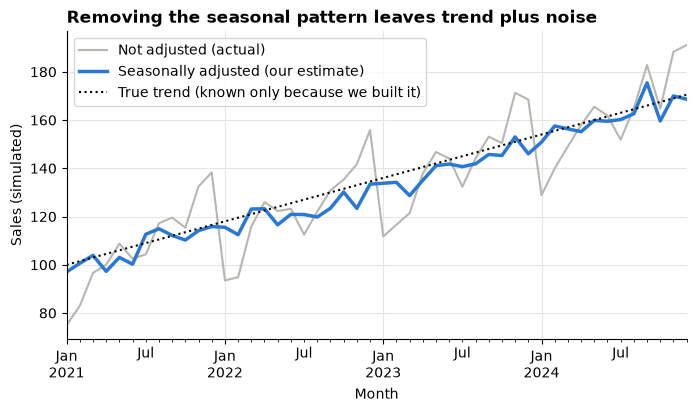

,estimated factor,true factor
month,,
1,-22.00,-25
2,-17.60,-20
3,-7.30,-5
4,2.80,0
5,5.70,5
6,2.30,0
7,-8.30,-5
8,2.30,0
9,7.40,10


In [7]:
sales = demo["sales"]
trend_est = sales.rolling(12, center=True).mean()
gap = sales - trend_est
seasonal_factor = gap.groupby(gap.index.month).mean()
adjusted = sales - seasonal_factor.reindex(sales.index.month).values

ax = sales.plot(color="#b8b6b0", label="Not adjusted (actual)")
adjusted.plot(ax=ax, color="#2a78d6", linewidth=2.5, label="Seasonally adjusted (our estimate)")
demo["trend"].plot(ax=ax, color="black", linestyle=":", label="True trend (known only because we built it)")
ax.set_title("Removing the seasonal pattern leaves trend plus noise")
ax.set_xlabel("Month")
ax.set_ylabel("Sales (simulated)")
ax.legend()
plt.show()

pd.DataFrame({"estimated factor": seasonal_factor.round(1), "true factor": season_by_month},
             index=pd.Index(range(1, 13), name="month"))

The estimated seasonal factors come out close to the true ones we built in, and the adjusted line follows the trend plus noise.

> **Annual rates**
>
> Some official monthly series are published as a **seasonally adjusted annual rate (SAAR)**: the adjusted monthly value multiplied up to a full year. A SAAR of 1,200 means "if every month were like this one, the year would total about 1,200". Divide by 12 to compare it with a monthly amount, and **never add up** annual-rate values across months.

> **Check your understanding 5**
>
> A news report says spending "fell 8% in January". Which would you rather see: the adjusted or the unadjusted series? Why?

---

## Part 6: Incomplete and missing periods

Two quiet traps.

**An incomplete last period.** If data were pulled on the 10th of a month, that month holds about a third of its orders. On a chart it looks like a collapse.

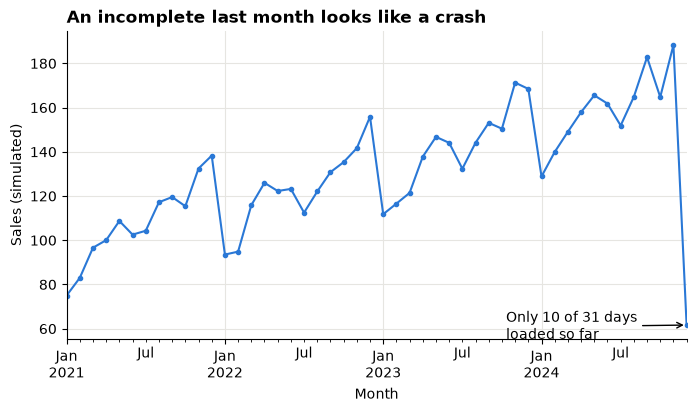

Last month MoM growth: -67.3%


In [8]:
cut = demo["sales"].copy()
cut.iloc[-1] = cut.iloc[-1] * 10 / 31        # data pulled on the 10th of the last month

ax = cut.plot(marker="o", markersize=3)
ax.annotate("Only 10 of 31 days\nloaded so far", xy=(cut.index[-1], cut.iloc[-1]),
            xytext=(-130, -10), textcoords="offset points",
            arrowprops={"arrowstyle": "->"})
ax.set_title("An incomplete last month looks like a crash")
ax.set_xlabel("Month")
ax.set_ylabel("Sales (simulated)")
plt.show()

print("Last month MoM growth:", f"{cut.pct_change().iloc[-1]:+.1%}")

**A missing month.** `pct_change()` compares each **row** with the row above. If a month is missing, "the row above" is two months earlier, and nothing warns you. The fix is to line the series up against the full calendar first.

In [9]:
gappy = demo["sales"].drop(pd.Timestamp("2024-06-01"))
print("Rows:", len(gappy), "| months in the calendar:", len(months))

wrong = gappy.pct_change().loc["2024-07-01"]
safe = gappy.reindex(months).pct_change(fill_method=None).loc["2024-07-01"]
print("July 2024 MoM, missing June ignored: ", f"{wrong:+.1%}  <- silently compared with May")
print("July 2024 MoM, after reindex:        ", safe, " <- no comparison available")

Rows: 47 | months in the calendar: 48
July 2024 MoM, missing June ignored:  -8.3%  <- silently compared with May
July 2024 MoM, after reindex:         nan  <- no comparison available


> **Rules for periods**
>
> 1. Check the first and last date, and whether the last period is complete.
> 2. Build the full calendar with `pd.date_range` and `reindex` against it, so gaps show as blanks.
> 3. Compare **like with like**: a part-year only with the same part of earlier years (for example January–September with January–September).

> **Check your understanding 6**
>
> A file has nine months of 2016 and twelve months of every earlier year. A colleague compares yearly totals and reports that 2016 was the weakest year. What should you check, and what fair comparison would you make instead?

---

## Part 7: Growth after filtering, the trap

You want a table of 2025 only. If you **filter first**, the earlier months the growth formula needs are gone.

In [10]:
monthly = df.groupby("order_month")["sales"].sum()

filter_first = monthly.loc["2025"].pct_change(periods=12)
compute_first = monthly.pct_change(periods=12).loc["2025"]

pd.DataFrame({"YoY, filter then compute": filter_first.map(as_pct),
              "YoY, compute then filter": compute_first.map(as_pct)}).head(4)

,"YoY, filter then compute","YoY, compute then filter"
order_month,,
2025-01-01,no comparison,+2.0%
2025-02-01,no comparison,+92.3%
2025-03-01,no comparison,+32.6%
2025-04-01,no comparison,+13.6%


> **Predict, then reveal**
>
> Before running the cell above: how many of the twelve 2025 months will have a YoY value when you filter first?

Filtering to one year leaves only twelve rows, so no row has a partner twelve rows above it. Every YoY value becomes blank ("no comparison").

> **Rule**
>
> **Compute growth on the complete series first, then filter or highlight the period you want to show.** Filtering by a group such as a segment is fine, because it applies to both months in the comparison; build that group's complete series first.

---

## Part 8: Worked case — Superstore monthly Sales

We put the pieces together on the retail orders.

### Step 1: Check the calendar

In [11]:
all_months = pd.date_range("2023-01-01", "2025-12-01", freq="MS")
print("First order month:", monthly.index.min().date(), "| last:", monthly.index.max().date())
print("Months expected:", len(all_months), "| months present:", len(monthly),
      "| missing:", len(all_months.difference(monthly.index)))
monthly = monthly.reindex(all_months)

First order month: 2023-01-01 | last: 2025-12-01
Months expected: 36 | months present: 36 | missing: 0


### Step 2: Trend and seasonality in one view

A light line for the actual months, a strong line for the trailing 12-month average, and a year-overlay chart for the season.

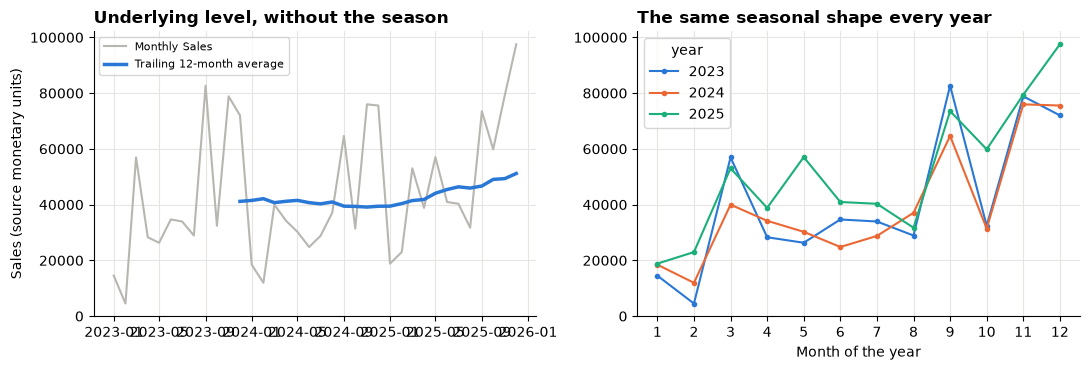

In [12]:
rolling_12 = monthly.rolling(12).mean()

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 3.8))
ax1.plot(monthly.index, monthly, color="#b8b6b0", label="Monthly Sales")
ax1.plot(rolling_12.index, rolling_12, color="#2a78d6", linewidth=2.5, label="Trailing 12-month average")
ax1.set_title("Underlying level, without the season")
ax1.set_ylabel("Sales (source monetary units)")
ax1.legend(fontsize=8)

overlay = pd.DataFrame({"year": monthly.index.year, "month": monthly.index.month, "sales": monthly.values})
overlay.pivot(index="month", columns="year", values="sales").plot(ax=ax2, marker="o", markersize=3)
ax2.set_title("The same seasonal shape every year")
ax2.set_xlabel("Month of the year")
ax2.set_xticks(range(1, 13))
fig.tight_layout()
plt.show()

### Step 3: Which comparison is fair for January 2025?

In [13]:
jan = pd.Timestamp("2025-01-01")
print("January 2025 Sales:", f"{monthly[jan]:,.0f}")
print("MoM (vs December 2024):", f"{monthly.pct_change()[jan]:+.1%}")
print("YoY (vs January 2024): ", f"{monthly.pct_change(periods=12)[jan]:+.1%}")

January 2025 Sales: 18,830
MoM (vs December 2024): -75.1%
YoY (vs January 2024):  +2.0%


Read the two growth figures above alongside the year-overlay chart. The month-on-month figure repeats the usual January drop; the year-on-year figure compares January with January. For a seasonal business, the YoY figure is the fair headline, and the trailing average shows whether the underlying level is rising.

---

## Summary

| Question | Tool | Trap to avoid |
|---|---|---|
| Is there a pattern by time of year? | Year-overlay chart | Reading one month in isolation |
| Did this month grow? | YoY for seasonal series; MoM for non-seasonal | Calling a seasonal dip a crash |
| What is the underlying level? | Trailing 12-month average | Forgetting it lags |
| When exactly did it turn? | Centred average (on history) | Expecting it for the latest months |
| How do different-sized series compare? | Index, base = 100 | Choosing an unusual base period |
| Is this month normal for the season? | Seasonally adjusted series | Adding up annual-rate values |
| Can I trust the comparison? | Full calendar, complete periods | Missing months, part-years, filtering first |

---

## Quiz

Answer these at the start of the next lecture. Write short answers.

1. Name the three components of a time series and give a one-line example of each.
2. Why can month-on-month growth mislead for a seasonal business?
3. What does year-on-year growth compare, and when can it still mislead?
4. A trailing and a centred 12-month average are drawn on the same series. Which turns later after a sudden change, and which is blank for the latest months?
5. An index with base year 2023 = 100 reads 112 in 2025. What does that mean?
6. What does a seasonally adjusted series remove, and why do official agencies publish one?
7. Why should you never fill a blank growth value with 0%?
8. You filter a monthly table to one year and then compute YoY growth. What happens, and what should you do instead?

---

## Lab briefing

In the **Lab** you:

1. Build the monthly Superstore series, check it is complete and read its seasons.
2. Calculate MoM and YoY growth and see how filtering removes the comparison.
3. Measure the share of orders on the returns list and build a three-panel dashboard.
4. Select one consistent series from official US construction spending, read its seasons and compare part-years fairly.
5. Debug a "75% crash" and a "weakest year ever" claim.
6. Write a five-sentence test recommendation for the commercial lead.

Open the [Session 7 lab](07_trends_and_growth_lab.md).